# Skill to weights: teach a model a skill with one short SFT run

A skill file (`SKILL.md`) works by sitting in the prompt on every request. This notebook trains it into the weights, so the model behaves the same way with the skill removed.

1. **Headroom.** Sample the base model on every case with and without the skill, and score each reply.
2. **Training rows.** Keep the replies that passed *with* the skill, on train cases only, and strip the skill out of their prompt.
3. **SFT.** A short serverless LoRA run on those rows.
4. **Result.** Score the tuned model, without the skill, on the held-out cases.

The worked example is [caveman](skills/caveman/SKILL.md): terse developer answers, no ceremony, every command kept exact. To use your own skill, change only the next cell. Expect about 15 minutes end to end.

In [1]:
# ---- What you bring. This is the only cell you need to edit. ----

BASE_MODEL = "accounts/fireworks/models/glm-5p3-flash"  # trained on serverless, sampled on serverless inference
TOKENIZER = "zai-org/GLM-5.3"                           # chat template the served model uses
REASONING_EFFORT = "low"                                # "" to omit

SKILL_PATH = "skills/caveman/SKILL.md"
CASES_PATH = "cases/caveman.jsonl"   # one JSON per line: id, split (train/test), category, prompt, labels
NEUTRAL_SYSTEM = "You are a helpful coding assistant."  # the prompt when the skill is NOT in context

# How many draws per case, and the SFT run.
K = 4
STEPS = 48
BATCH_SIZE = 4
RANK = 16
LEARNING_RATE = 1e-4


# Pass/fail for one reply. `case["labels"]` holds whatever your grader needs;
# the model never sees it. This one checks caveman in plain Python. To use an
# LLM judge instead, call it here and return its verdict as a bool.
import re

CEREMONY = [
    "sure", "certainly", "of course", "great question", "good question", "happy to help",
    "hope this helps", "let me", "i'll ", "i will ", "here's how", "here is how",
    "feel free", "let me know", "don't hesitate", "in summary", "to summarize",
]
FILLER = ["just", "really", "basically", "actually", "simply"]
PERFORMED = ["caveman:", "me think", "ugh"]
WARNING_WORDS = [
    "permanent", "irreversible", "cannot be undone", "can't be undone", "destroy",
    "discard", "lose", "lost", "overwrite", "clobber", "careful", "warning",
    "rotate", "revoke", "exposed", "for everyone",
]


def _prose(reply):
    """The reply with fenced and inline code removed, lowercased."""
    text = re.sub(r"```.*?```", " ", reply, flags=re.DOTALL)
    text = re.sub(r"`[^`]*`", " ", text)
    return text.lower()


def score(case, reply):
    labels = case["labels"]
    prose = _prose(reply)
    first = prose.strip().split("\n", 1)[0]
    lowered = reply.lower()
    if len(reply.split()) > labels["max_words"]:
        return False
    for item in labels["must_include"]:
        options = [item] if isinstance(item, str) else item
        if not any(option.lower() in lowered for option in options):
            return False
    if any(first.startswith(phrase) for phrase in CEREMONY):
        return False
    if any(phrase in prose for phrase in CEREMONY[4:]):
        return False
    if any(re.search(rf"\b{word}\b", prose) for word in FILLER):
        return False
    if any(phrase in prose for phrase in PERFORMED):
        return False
    if labels.get("warning") and not any(word in prose for word in WARNING_WORDS):
        return False
    return True

## Setup

In [2]:
import json
import math
import os
import time
from concurrent.futures import ThreadPoolExecutor, as_completed
from pathlib import Path

import matplotlib.pyplot as plt
from dotenv import load_dotenv
from IPython.display import HTML, display
from openai import OpenAI
from tqdm.auto import tqdm

load_dotenv(Path(".env"))
assert os.environ.get("FIREWORKS_API_KEY"), "set FIREWORKS_API_KEY in .env"

COMPLETION_BUDGET_FLOOR = 10_000  # reasoning models think first; a smaller cap returns empty replies
MAX_TOKENS = COMPLETION_BUDGET_FLOOR

skill_text = Path(SKILL_PATH).read_text()
if skill_text.startswith("---"):
    skill_text = skill_text.split("\n---", 1)[1]
skill_text = skill_text.strip()
cases = [json.loads(line) for line in Path(CASES_PATH).read_text().splitlines() if line.strip()]
train_cases = [c for c in cases if c["split"] == "train"]
test_cases = [c for c in cases if c["split"] == "test"]
assert train_cases and test_cases, "need both a train and a test split"

RUN_ID = time.strftime("%m%d%H%M")
RUNS = Path("runs") / RUN_ID
RUNS.mkdir(parents=True, exist_ok=True)
infer = OpenAI(api_key=os.environ["FIREWORKS_API_KEY"], base_url="https://api.fireworks.ai/inference/v1",
               timeout=600, max_retries=0)

print(f"skill {len(skill_text)} chars | cases {len(train_cases)} train / {len(test_cases)} test | run {RUN_ID}")
print(f"calls: {len(cases) * K * 2} base generations, then {len(test_cases) * K} tuned generations. "
      f"SFT: {STEPS} steps at batch {BATCH_SIZE}.")

skill 4429 chars | cases 24 train / 16 test | run 10261316
calls: 320 base generations, then 64 tuned generations. SFT: 48 steps at batch 4.


## 1. Headroom: base model with and without the skill

If the skill doesn't beat base here, training has nothing to copy. Stop and fix the skill or the cases.

In [3]:
def messages(prompt, with_skill):
    return [{"role": "system", "content": skill_text if with_skill else NEUTRAL_SYSTEM},
            {"role": "user", "content": prompt}]


def chat(msgs):
    extra = {"reasoning_effort": REASONING_EFFORT} if REASONING_EFFORT else {}
    response = infer.chat.completions.create(model=BASE_MODEL, messages=msgs, temperature=1.0,
                                             max_tokens=MAX_TOKENS, extra_body=extra)
    return (response.choices[0].message.content or "").strip()


def sample_all(case_list, generate, desc, workers):
    """K draws per case. Returns rows with the reply and its score. Empty or failed replies are not zeros."""
    jobs = [(c, d) for c in case_list for d in range(K)]
    rows, failed = [], 0
    with ThreadPoolExecutor(max_workers=workers) as pool:
        futures = {pool.submit(generate, c): (c, d) for c, d in jobs}
        bar = tqdm(as_completed(futures), total=len(jobs), desc=desc, unit="reply")
        for future in bar:
            case, draw = futures[future]
            try:
                reply = future.result()
            except Exception as exc:  # noqa: BLE001
                failed += 1
                tqdm.write(f"{case['id']} draw {draw}: {type(exc).__name__}: {exc}"[:200])
                continue
            if not reply:
                failed += 1
                continue
            rows.append({"id": case["id"], "split": case["split"], "draw": draw, "reply": reply,
                         "passed": bool(score(case, reply))})
            bar.set_postfix(passed=sum(r["passed"] for r in rows), failed=failed)
    if failed > 0.05 * len(jobs):
        raise RuntimeError(f"{desc}: {failed}/{len(jobs)} replies empty or failed. Fix that before trusting a score.")
    return rows


base_rows = sample_all(cases, lambda c: chat(messages(c["prompt"], False)), "base, no skill", 16)
skill_rows = sample_all(cases, lambda c: chat(messages(c["prompt"], True)), "base + skill", 16)
(RUNS / "base.json").write_text(json.dumps(base_rows))
(RUNS / "skill.json").write_text(json.dumps(skill_rows))


def rate(rows, split="test"):
    kept = [r for r in rows if r["split"] == split]
    return sum(r["passed"] for r in kept) / len(kept)


print(f"held-out pass@1: base {rate(base_rows):.0%}, base + skill {rate(skill_rows):.0%}")

base, no skill:   0%|          | 0/160 [00:00<?, ?reply/s]

base + skill:   0%|          | 0/160 [00:00<?, ?reply/s]

held-out pass@1: base 9%, base + skill 62%


## 2. Training rows

Each row is a train case's prompt under `NEUTRAL_SYSTEM` (no skill), followed by a reply that passed *with* the skill. The model learns to give the skilled answer without being told the skill.

In [4]:
by_id = {c["id"]: c for c in cases}
rows = [
    [{"role": "system", "content": NEUTRAL_SYSTEM},
     {"role": "user", "content": by_id[r["id"]]["prompt"]},
     {"role": "assistant", "content": r["reply"]}]
    for r in skill_rows if r["split"] == "train" and r["passed"]
][:100]
assert rows, "no passing skill replies on the train split; nothing to train on"
assert not any(skill_text in m["content"] for row in rows for m in row[:2]), "skill text leaked into a training prompt"
print(f"{len(rows)} training rows from {len(train_cases)} train cases")
print(json.dumps(rows[0], indent=1)[:900])

56 training rows from 24 train cases
[
 {
  "role": "system",
  "content": "You are a helpful coding assistant."
 },
 {
  "role": "user",
  "content": "My Python script fails with `ModuleNotFoundError: No module named 'yaml'`. What do I do?"
 },
 {
  "role": "assistant",
  "content": "PyYAML not installed. Fix:\n\n```bash\npip install pyyaml\n```\n\nModule name `yaml`, package name `pyyaml` \u2014 `pip install yaml` installs wrong package. If project uses requirements.txt or pyproject.toml, add `pyyaml` there too."
 }
]


## 3. Connect to serverless training and check the renderer

Base replies come from chat completions. The tuned model is sampled through the cookbook renderer. If the two build different prompts, base and tuned aren't being compared fairly, so this cell stops.

In [5]:
import transformers
from fireworks.training.sdk import FiretitanServiceClient
from fireworks.training.sdk import types as fw_types
from fireworks.training.sdk.client import FIRETITAN_TINKER_CLIENT_CONFIG
from fireworks.training.sdk.sampling import AdaptiveConcurrencyController
import training.renderer  # noqa: F401  (registers the cookbook renderers)
from training.utils.supervised import build_renderer, render_messages_to_datum

tokenizer = transformers.AutoTokenizer.from_pretrained(TOKENIZER, trust_remote_code=True)
renderer = build_renderer(tokenizer, TOKENIZER)
if REASONING_EFFORT:
    renderer = type(renderer)(tokenizer, reasoning_effort=REASONING_EFFORT)
template_kwargs = {"reasoning_effort": REASONING_EFFORT} if REASONING_EFFORT else {}
_msgs = messages(test_cases[0]["prompt"], False)
_hf = tokenizer.encode(tokenizer.apply_chat_template(_msgs, tokenize=False, add_generation_prompt=True,
                                                     **template_kwargs), add_special_tokens=False)
assert renderer.build_generation_prompt(_msgs).to_ints() == _hf, "renderer and chat template disagree"
print(f"renderer {type(renderer).__name__} matches the chat template ({len(_hf)} tokens)")

service = FiretitanServiceClient(api_key=os.environ["FIREWORKS_API_KEY"],
                                 base_url="https://api.fireworks.ai/training/v1/serverless",
                                 _client_config={**FIRETITAN_TINKER_CLIENT_CONFIG, "use_pyqwest_transport": False})
training_client = service.create_lora_training_client(base_model=BASE_MODEL, rank=RANK)
SAMPLE_PARAMS = fw_types.SamplingParams(max_tokens=MAX_TOKENS, temperature=1.0, stop=renderer.get_stop_sequences())


def make_sampler(path):
    return service.create_sampling_client(model_path=path, tokenizer=tokenizer,
                                          concurrency_controller=AdaptiveConcurrencyController())


def sample_tuned(sampler, prompt):
    model_input = fw_types.ModelInput.from_ints(renderer.build_generation_prompt(messages(prompt, False)).to_ints())
    result = sampler.sample(prompt=model_input, num_samples=1, sampling_params=SAMPLE_PARAMS).result(timeout=900)
    message, _ = renderer.parse_response(list(result.sequences[0].tokens))
    content = message.get("content") if isinstance(message, dict) else getattr(message, "content", "")
    if isinstance(content, list):
        content = "".join(p if isinstance(p, str) else str(p.get("text") or "") for p in content)
    return (content or "").strip()


t0 = time.time()
sample_tuned(make_sampler(training_client.save_weights_for_sampler(f"s2w-{RUN_ID}-p").result().path),
             "Reply with the single word ok.")
print(f"training sampler warm after {time.time() - t0:.0f}s (cold start, not training time)")

/Users/sinan/forge-workshops/.venv/lib/python3.14/site-packages/fireworks/training/sdk/_core/_compat.py:46: UserWarning: Core Pydantic V1 functionality isn't compatible with Python 3.14 or greater.
  from pydantic.v1.typing import (


renderer GLM53Renderer matches the chat template (47 tokens)


prefill_queue_duration is unavailable; AdaptiveConcurrencyController is using HTTP 429/503 and transport-error congestion signals instead


training sampler warm after 7s (cold start, not training time)


## 4. SFT

In [6]:
datums = [render_messages_to_datum(row, renderer=renderer).datum for row in rows]
adam = fw_types.AdamParams(learning_rate=LEARNING_RATE, beta1=0.9, beta2=0.95, eps=1e-12, weight_decay=0.0)
t0 = time.time()
for step in tqdm(range(STEPS), desc="SFT", unit="step"):
    batch = [datums[(step * BATCH_SIZE + i) % len(datums)] for i in range(min(BATCH_SIZE, len(datums)))]
    training_client.forward_backward(batch, "cross_entropy").result()
    training_client.optim_step(adam).result()
    if (step + 1) % 8 == 0:
        tqdm.write(f"step {step + 1}/{STEPS}  {(time.time() - t0) / 60:.1f} min")
tuned_path = training_client.save_weights_for_sampler(f"s2w-{RUN_ID}").result().path
print(f"{STEPS} steps ({STEPS * BATCH_SIZE / len(datums):.1f} passes over {len(datums)} rows) "
      f"in {(time.time() - t0) / 60:.1f} min -> {tuned_path}")

SFT:   0%|          | 0/48 [00:00<?, ?step/s]

step 8/48  1.1 min
step 16/48  2.2 min
step 24/48  3.3 min
step 32/48  4.4 min
step 40/48  5.5 min
step 48/48  6.6 min
48 steps (3.4 passes over 56 rows) in 6.7 min -> pyroworks/run-e4769defa9d34a3aa6957d3da5eaba14/s2w-10261316-7d3c7095


## 5. Score the tuned model, no skill in the prompt

Same held-out cases and same `score` function. Fan-out stays at 8 against the training sampler.

In [7]:
tuned_sampler = make_sampler(tuned_path)
tuned_rows = sample_all(test_cases, lambda c: sample_tuned(tuned_sampler, c["prompt"]), "tuned, no skill", 8)
(RUNS / "tuned.json").write_text(json.dumps(tuned_rows))
print(f"held-out pass@1: base {rate(base_rows):.0%}, base + skill {rate(skill_rows):.0%}, "
      f"tuned {rate(tuned_rows):.0%}")

tuned, no skill:   0%|          | 0/64 [00:00<?, ?reply/s]

prefill_queue_duration is unavailable; AdaptiveConcurrencyController is using HTTP 429/503 and transport-error congestion signals instead


tst-09 draw 0: HTTPStatusError: Client error '403 Forbidden' for url 'https://api.fireworks.ai/training/v1/serverless/inference/v1/completions'
For more information check: https://developer.mozilla.or
tst-14 draw 0: HTTPStatusError: Client error '403 Forbidden' for url 'https://api.fireworks.ai/training/v1/serverless/inference/v1/completions'
For more information check: https://developer.mozilla.or
tst-15 draw 0: HTTPStatusError: Client error '403 Forbidden' for url 'https://api.fireworks.ai/training/v1/serverless/inference/v1/completions'
For more information check: https://developer.mozilla.or
held-out pass@1: base 9%, base + skill 62%, tuned 67%


## 6. Results

- **pass@1:** how often one reply passes.
- **pass@k:** does at least one of k replies pass?
- **pass^k:** do all k pass? This measures consistency.

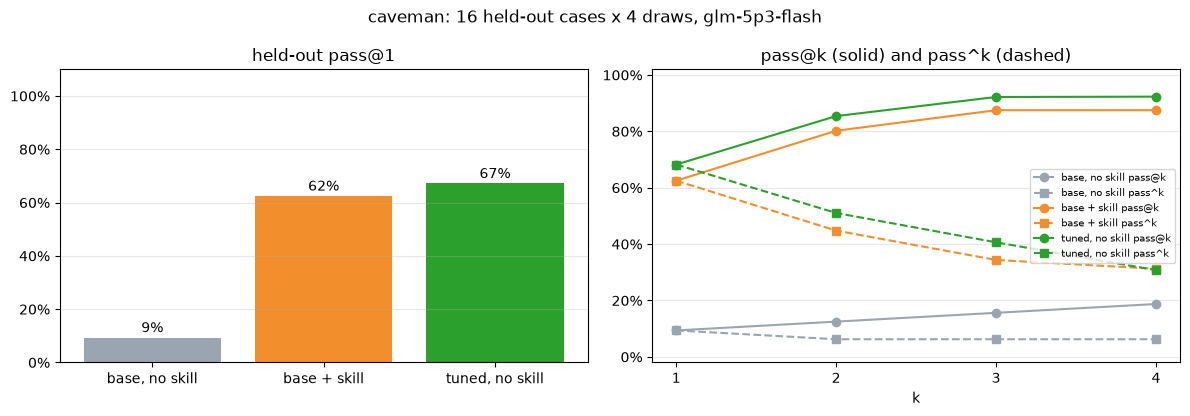

In [8]:
def pass_at_k(n, c, k):
    return 1.0 if n - c < k else 1.0 - math.comb(n - c, k) / math.comb(n, k)


def pass_pow_k(n, c, k):
    return 0.0 if c < k else math.comb(c, k) / math.comb(n, k)


def curve(rows, fn):
    groups = {}
    for r in rows:
        if r["split"] == "test":
            groups.setdefault(r["id"], []).append(r["passed"])
    return [sum(fn(len(g), sum(g), k) for g in groups.values() if len(g) >= k) /
            max(1, sum(len(g) >= k for g in groups.values())) for k in range(1, K + 1)]


series = {"base, no skill": base_rows, "base + skill": skill_rows, "tuned, no skill": tuned_rows}
colors = ["#9aa5b1", "#f28e2b", "#2ca02c"]
fig, (bars, curves) = plt.subplots(1, 2, figsize=(12, 4.2))
for i, (name, rs) in enumerate(series.items()):
    value = rate(rs)
    bars.bar(i, value, color=colors[i])
    bars.text(i, value + 0.02, f"{value:.0%}", ha="center")
    curves.plot(range(1, K + 1), curve(rs, pass_at_k), "o-", color=colors[i], label=f"{name} pass@k")
    curves.plot(range(1, K + 1), curve(rs, pass_pow_k), "s--", color=colors[i], label=f"{name} pass^k")
bars.set_xticks(range(3), list(series))
bars.set_ylim(0, 1.1)
bars.set_title("held-out pass@1")
curves.set_xticks(range(1, K + 1))
curves.set_ylim(-0.02, 1.02)
curves.set_xlabel("k")
curves.set_title("pass@k (solid) and pass^k (dashed)")
curves.legend(fontsize=7)
for ax in (bars, curves):
    ax.yaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
    ax.grid(axis="y", alpha=0.3)
fig.suptitle(f"{Path(SKILL_PATH).parent.name}: {len(test_cases)} held-out cases x {K} draws, {BASE_MODEL.split('/')[-1]}")
fig.tight_layout()
fig.savefig(RUNS / "result.png", dpi=150)
plt.show()

## 7. Promote the tuned weights, then close the session

Promotion turns the session checkpoint into a model you can deploy. Session checkpoints stop being servable once the session closes, so promote first.

In [13]:
from fireworks.training.sdk.fireworks_client import FireworksClient

fw = FireworksClient(api_key=os.environ["FIREWORKS_API_KEY"])
_, trainer_run, snap_name = tuned_path.split("/")
ckpt = next(r for r in fw.list_training_session_checkpoints(service.training_session_name)
            if r["name"].endswith(f"/{trainer_run}-{snap_name}") and r.get("promotable"))
promoted = fw.promote_session_checkpoint(name=ckpt["name"], output_model_id=f"s2w-{RUN_ID}", base_model=BASE_MODEL)
print(f"accounts/{fw.account_id}/models/s2w-{RUN_ID}", promoted.get("state"))

accounts/pyroworks/models/s2w-10261316 READY


In [14]:
service.close()
print("training session closed")

training session closed
